In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the cleaned dataset
file_path = Path("../data/coffee_shop_cleaned.csv")
df = pd.read_csv(file_path)

# Ensure correct data types
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"], errors="coerce"
)

df["unit_price"] = pd.to_numeric(
    df["unit_price"], errors="coerce"
)

df["Revenue"] = pd.to_numeric(
    df["Revenue"], errors="coerce"
)

print("Analysis dataset loaded!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Analysis dataset loaded!
Rows: 149116
Columns: 14


In [2]:
total_revenue = df["Revenue"].sum()

total_transactions = df["transaction_id"].nunique()

total_quantity_sold = df["transaction_qty"].sum()

average_transaction_value = (
    total_revenue / total_transactions
    if total_transactions > 0 else 0
)

kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Transactions",
        "Total Quantity Sold",
        "Average Transaction Value"
    ],
    "Value": [
        total_revenue,
        total_transactions,
        total_quantity_sold,
        average_transaction_value
    ]
})

display(kpis)

,KPI,Value
0,Total Revenue,698812.330000
1,Total Transactions,149116.000000
2,Total Quantity Sold,214254.000000
3,Average Transaction Value,4.686367


In [ ]:
#revenue by product category
category_sales = (
    df.groupby("product_category", dropna=False)["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(category_sales)

,product_category,Revenue
0,Coffee,269952.45
1,Tea,196405.95
2,Bakery,82315.64
3,Drinking Chocolate,72416.00
4,Coffee Beans,40085.25
5,Branded,13607.00
6,Loose Tea,11213.60
7,Flavours,8408.80
8,Packaged Chocolate,4407.64


In [ ]:
#revenue by store
store_sales = (
    df.groupby("store_location", dropna=False)["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(store_sales)

,store_location,Revenue
0,Hell'S Kitchen,236511.17
1,Astoria,232243.91
2,Lower Manhattan,230057.25


In [9]:
#monthly revenue
df["month"] = df["transaction_date"].dt.to_period("M").astype(str)

monthly_sales = (
    df.groupby("month")["Revenue"]
    .sum()
    .reset_index()
)

display(monthly_sales)

,month,Revenue
0,2023-01,81650.94
1,2023-02,76125.09
2,2023-03,98823.38
3,2023-04,118890.28
4,2023-05,156674.00
5,2023-06,166364.93
6,2023-07,40.50
7,2023-08,83.55
8,2023-09,23.76
9,2023-10,52.95


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"

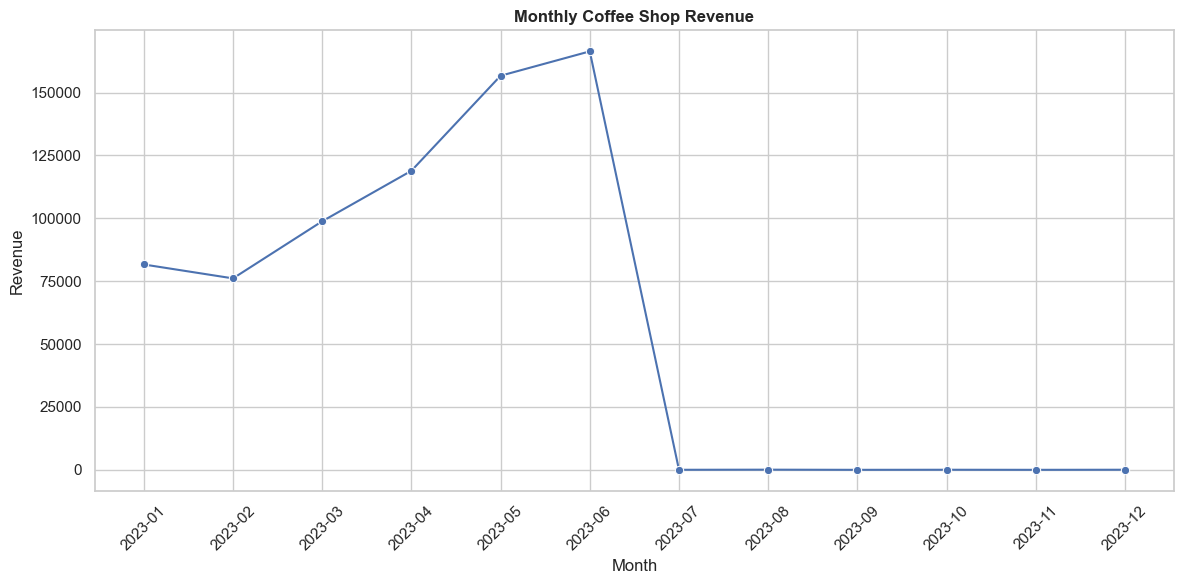

In [11]:
monthly_sales = (
    df.groupby(df["transaction_date"].dt.to_period("M"))["Revenue"]
    .sum()
    .sort_index()
)

monthly_sales.index = monthly_sales.index.astype(str)

fig, ax = plt.subplots()

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o",
    ax=ax
)

ax.set_title("Monthly Coffee Shop Revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

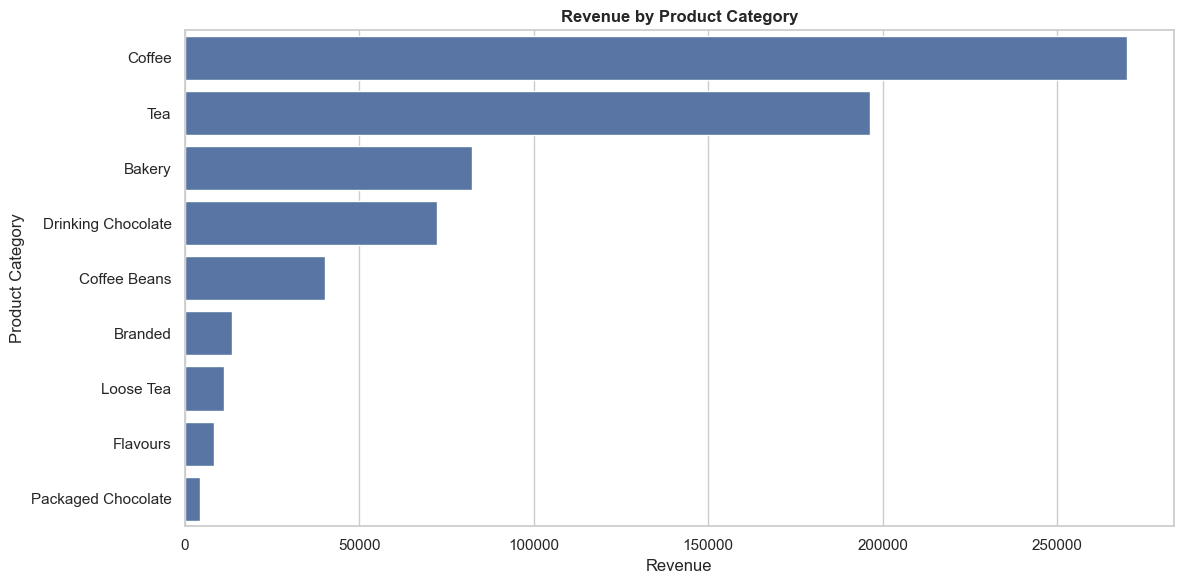

In [12]:
category_sales = (
    df.groupby("product_category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots()

sns.barplot(
    x=category_sales.values,
    y=category_sales.index,
    ax=ax
)

ax.set_title("Revenue by Product Category")
ax.set_xlabel("Revenue")
ax.set_ylabel("Product Category")
plt.tight_layout()
plt.show()

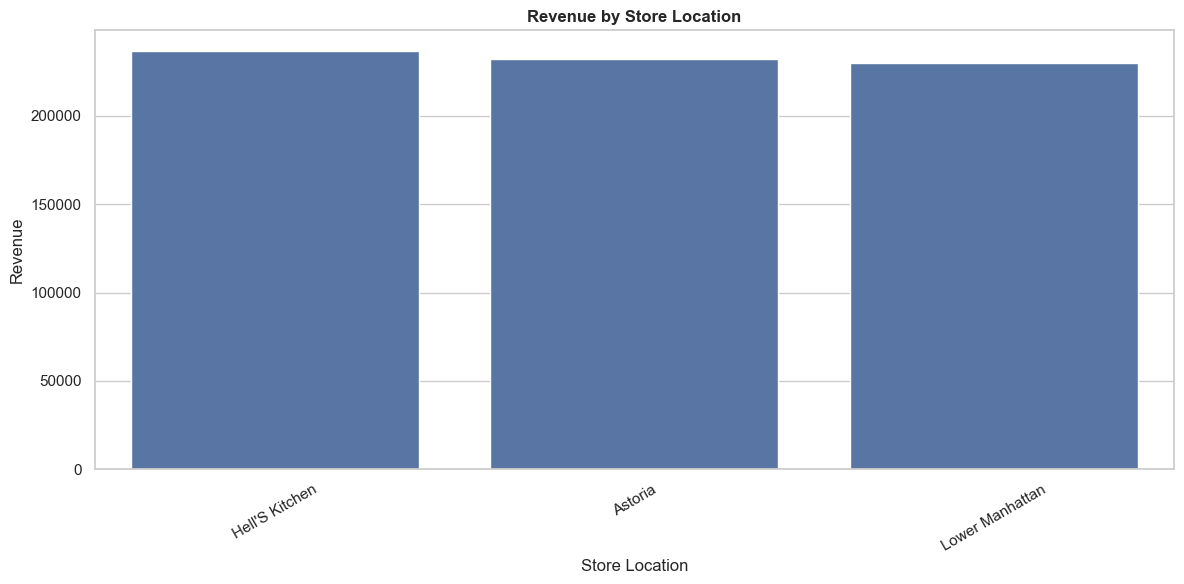

In [13]:
store_sales = (
    df.groupby("store_location")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots()

sns.barplot(
    x=store_sales.index,
    y=store_sales.values,
    ax=ax
)

ax.set_title("Revenue by Store Location")
ax.set_xlabel("Store Location")
ax.set_ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

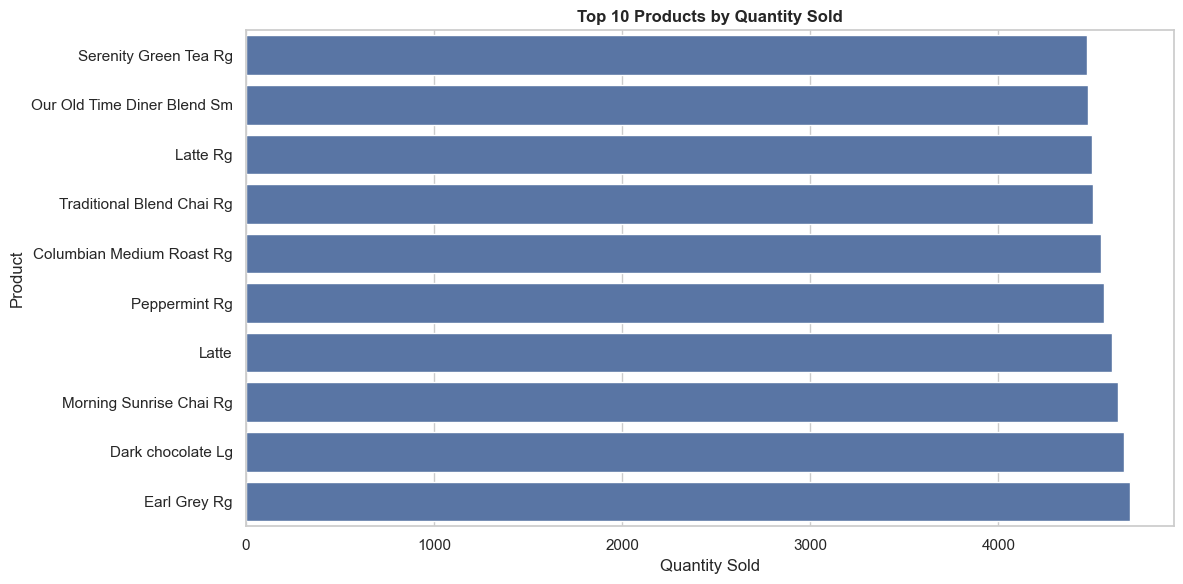

In [14]:
top_products = (
    df.groupby("product_detail")["transaction_qty"]
    .sum()
    .nlargest(10)
    .sort_values()
)

fig, ax = plt.subplots()

sns.barplot(
    x=top_products.values,
    y=top_products.index,
    ax=ax
)

ax.set_title("Top 10 Products by Quantity Sold")
ax.set_xlabel("Quantity Sold")
ax.set_ylabel("Product")
plt.tight_layout()
plt.show()